# 02 - Numerical convergence
Observed (not assumed) convergence of trees and finite differences.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from optpricer import Option, MarketData, price, price_all, bsm
pd.set_option("display.width", 160); pd.set_option("display.precision", 6)

,n,CRR,CRR avg,LR
0,51,0.028899,0.009109,-1.514910e-04
1,101,0.009144,0.007481,-3.920031e-05
2,201,0.002840,0.003566,-9.973193e-06
3,401,-0.003429,0.000383,-2.515402e-06
4,801,-0.001887,0.000117,-6.316450e-07


{'CRR': 0.93, 'CRR avg': 1.7, 'LR': 1.99}


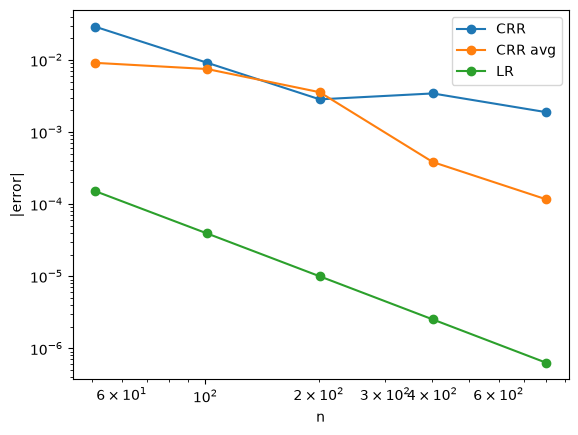

In [2]:
from optpricer.binomial import crr, crr_averaged, leisen_reimer
from optpricer.validation import observed_order
m, o = MarketData(100, 0.05, 0.0, 0.2), Option("call", 105, 1.0)
ref = bsm.price(100, 105, 1.0, 0.05, 0.0, 0.2, "call")
ns = np.array([51, 101, 201, 401, 801])
tab = pd.DataFrame({"n": ns,
    "CRR": [crr(o, m, n).price - ref for n in ns],
    "CRR avg": [crr_averaged(o, m, n).price - ref for n in ns],
    "LR": [leisen_reimer(o, m, n).price - ref for n in ns]})
display(tab)
print({c: round(-observed_order(ns, tab[c]), 2) for c in ["CRR", "CRR avg", "LR"]})
ax = tab.set_index("n").abs().plot(logy=True, logx=True, marker="o"); ax.set_ylabel("|error|");

In [3]:
from optpricer.pde import fd_price
o = Option("call", 100, 1.0)
rows = []
for M in (100, 200, 400, 800):
    r = fd_price(o, m, "cn", M, 1600)
    rows.append({"M": M, "dx": r.diagnostics["dx"], "error": r.price - bsm.price(100, 100, 1, 0.05, 0, 0.2, "call")})
sp = pd.DataFrame(rows); display(sp)
print("observed spatial order:", round(observed_order(sp.dx, sp.error), 2))

,M,dx,error
0,100,0.024600,0.002145
1,200,0.012300,0.000538
2,400,0.006150,0.000135
3,800,0.003075,0.000033


observed spatial order: 2.0


In [4]:
from optpricer import UnstableSchemeError
try:
    fd_price(o, m, "explicit", 200, 50)
except UnstableSchemeError as exc:
    print("Rejected by default:", str(exc)[:160], "...")
bad = fd_price(o, m, "explicit", 100, 60, allow_unstable=True)
print("intentional unstable run: price =", round(bad.price, 2), "max|g| =", round(bad.diagnostics["von_neumann_max_amplification"], 3))

Rejected by default: explicit scheme unstable: max |g| = 9.5767 > 1.0000 (dtau=0.02, dx=0.0123, sigma^2 dtau/dx^2=5.288). Increase n_time to at least about 269, use 'implicit'/'cn', ...
intentional unstable run: price = -1129.39 max|g| = 1.204
